# Leitura da Base:

In [13]:
# Bibliotecas
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Caminho relativo do arquivo CSV
raiz = Path.cwd().parent
df_raw = pd.read_csv(raiz / "data" / "credit_risk_dataset.csv")

nomes_pt = {
    "person_age": "idade",
    "person_income": "renda_anual",
    "person_home_ownership": "tipo_moradia",
    "person_emp_length": "tempo_emprego_anos",
    "loan_intent": "finalidade_emprestimo",
    "loan_grade": "nota_credito",
    "loan_amnt": "valor_emprestimo",
    "loan_int_rate": "taxa_juros",
    "loan_status": "inadimplente",
    "loan_percent_income": "percentual_renda",
    "cb_person_default_on_file": "historico_inadimplencia",
    "cb_person_cred_hist_length": "tempo_historico_credito",
}

valores_pt = {
    "tipo_moradia": {
        "RENT": "Aluguel",
        "OWN": "Própria",
        "MORTGAGE": "Financiada",
        "OTHER": "Outro",
    },
    "finalidade_emprestimo": {
        "PERSONAL": "Pessoal",
        "EDUCATION": "Educação",
        "MEDICAL": "Saúde",
        "VENTURE": "Negócio",
        "HOMEIMPROVEMENT": "Reforma",
        "DEBTCONSOLIDATION": "Quitar dívidas",
    },
    "historico_inadimplencia": {"Y": "Sim", "N": "Não"},
}

df_pt = df_raw.rename(columns=nomes_pt)
for coluna, mapa in valores_pt.items():
    df_pt[coluna] = df_pt[coluna].map(mapa)

df_pt.head()

,idade,renda_anual,tipo_moradia,tempo_emprego_anos,finalidade_emprestimo,nota_credito,valor_emprestimo,taxa_juros,inadimplente,percentual_renda,historico_inadimplencia,tempo_historico_credito
0,22,59000,Aluguel,123.0,Pessoal,D,35000,16.02,1,0.59,Sim,3
1,21,9600,Própria,5.0,Educação,B,1000,11.14,0,0.10,Não,2
2,25,9600,Financiada,1.0,Saúde,C,5500,12.87,1,0.57,Não,3
3,23,65500,Aluguel,4.0,Saúde,C,35000,15.23,1,0.53,Não,2
4,24,54400,Aluguel,8.0,Saúde,C,35000,14.27,1,0.55,Sim,4


**Para facilitar a leitura dos dados, traduzi-os para o português, criando uma cópia sem alterar o DataFrame original.**

# Dimensões, tipos e resumo estatísticos:

In [14]:
# Dimensões e tipos
print(f"Linhas: {df_pt.shape[0]} | Colunas: {df_pt.shape[1]}")
df_pt.info()

# Resumo estatístico (transposto para facilitar a leitura)
df_pt.describe().T

Linhas: 32581 | Colunas: 12
<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   idade                    32581 non-null  int64  
 1   renda_anual              32581 non-null  int64  
 2   tipo_moradia             32581 non-null  str    
 3   tempo_emprego_anos       31686 non-null  float64
 4   finalidade_emprestimo    32581 non-null  str    
 5   nota_credito             32581 non-null  str    
 6   valor_emprestimo         32581 non-null  int64  
 7   taxa_juros               29465 non-null  float64
 8   inadimplente             32581 non-null  int64  
 9   percentual_renda         32581 non-null  float64
 10  historico_inadimplencia  32581 non-null  str    
 11  tempo_historico_credito  32581 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 3.0 MB


,count,mean,std,min,25%,50%,75%,max
idade,32581.0,27.734600,6.348078,20.00,23.00,26.00,30.00,144.00
renda_anual,32581.0,66074.848470,61983.119168,4000.00,38500.00,55000.00,79200.00,6000000.00
tempo_emprego_anos,31686.0,4.789686,4.142630,0.00,2.00,4.00,7.00,123.00
valor_emprestimo,32581.0,9589.371106,6322.086646,500.00,5000.00,8000.00,12200.00,35000.00
taxa_juros,29465.0,11.011695,3.240459,5.42,7.90,10.99,13.47,23.22
inadimplente,32581.0,0.218164,0.413006,0.00,0.00,0.00,0.00,1.00
percentual_renda,32581.0,0.170203,0.106782,0.00,0.09,0.15,0.23,0.83
tempo_historico_credito,32581.0,5.804211,4.055001,2.00,3.00,4.00,8.00,30.00


**Observações do `info()` e do `describe()`:**
- **Dimensões:** 32.581 linhas e 12 colunas.
- **Tipos:** 4 colunas categóricas (texto): `tipo_moradia`, `finalidade_emprestimo`, `nota_credito` e `historico_inadimplencia`. As outras 8 são numéricas.
- **Nulos:** `tempo_emprego_anos` (31.686 de 32.581) e `taxa_juros` (29.465 de 32.581).
- **Alvo:** a média de `inadimplente` é 0,22, ou seja, cerca de 22% dos clientes são inadimplentes. A base é desbalanceada.
- **Valores suspeitos:** idade máxima de 144 anos e tempo de emprego máximo de 123 anos são impossíveis. Renda anual máxima de 6 milhões, muito acima do 3º quartil (79.200), precisa ser investigada.

# Distribuição da variável alvo

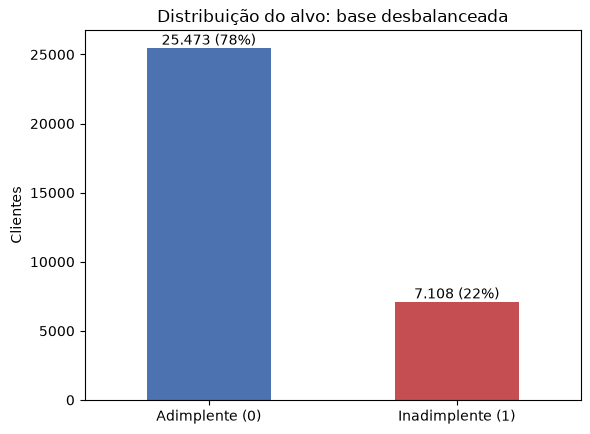

In [ ]:
# Quantidade de clientes em cada classe do alvo
rotulos = {0: "Adimplente (0)", 1: "Inadimplente (1)"}
contagem = df_pt["inadimplente"].map(rotulos).value_counts()

ax = contagem.plot(kind="bar", color=["#4C72B0", "#C44E52"], rot=0)
ax.bar_label(
    ax.containers[0],
    labels=[f"{v:,} ({v / len(df_pt):.0%})".replace(",", ".") for v in contagem],
)
ax.set_title("Distribuição do alvo: base desbalanceada")
ax.set_xlabel("")
ax.set_ylabel("Clientes")
plt.show()

**Observação:** a base é desbalanceada: 25.473 clientes adimplentes (78%) contra 7.108 inadimplentes (22%). Um modelo que "chutasse" sempre adimplente acertaria 78% das vezes sem aprender nada, por isso a acurácia não serve como métrica principal. Por isso vamos avaliar os modelos por Recall, F1-Score e ROC-AUC, e tratar o desbalanceamento com `class_weight="balanced"`, aplicado apenas no treino.


# Outliers nas variáveis numéricas

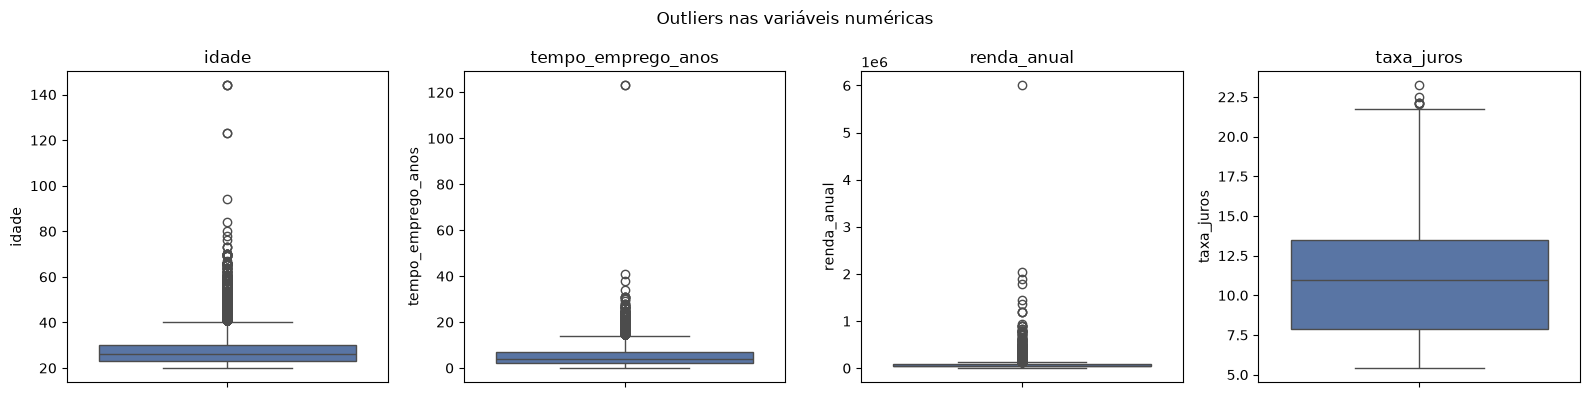

In [16]:
# Boxplot das variáveis numéricas com valores suspeitos no describe()

colunas = ["idade", "tempo_emprego_anos", "renda_anual", "taxa_juros"]
fig, eixos = plt.subplots(1, 4, figsize=(16, 4))

for eixo, coluna in zip(eixos, colunas):
    sns.boxplot(y=df_pt[coluna], ax=eixo, color="#4C72B0")
    eixo.set_title(coluna)

plt.suptitle("Outliers nas variáveis numéricas")
plt.tight_layout()
plt.show()

**Observação:**
- **idade:** a maioria dos clientes está entre 20 e 40 anos. Há muitos pontos entre 40 e 80 anos, que a regra do boxplot marca como outliers, mas são idades plausíveis. Os pontos isolados acima de 120 anos são impossíveis.
- **tempo_emprego_anos:** a maioria está entre 0 e 20 anos. Os pontos até ~40 anos são plausíveis; o ponto isolado em 123 anos é impossível.
- **renda_anual:** a caixa fica "esmagada" perto de zero por causa de poucos valores muito altos, com um ponto isolado em 6 milhões e alguns entre 1 e 2 milhões.
- **taxa_juros:** distribuição bem comportada, com poucos pontos pouco acima do limite superior (~22.5%).

**Conclusão para a limpeza:** a regra do boxplot (intervalo interquartil) marca como outlier muitos valores reais, como clientes de 50 ou 60 anos. Por isso, ela não será usada para remover dados automaticamente. Serão removidos apenas os valores impossíveis (erros de cadastro), e os valores extremos reais serão mantidos.

# Matriz de correlação

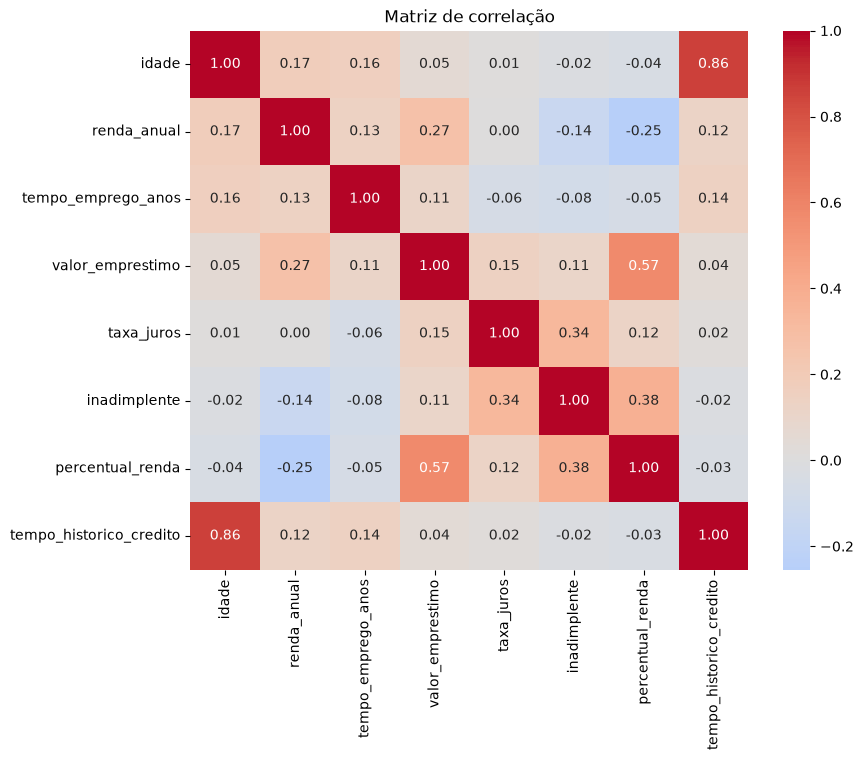

In [ ]:
# Correlação entra as variáveis numéricas (inclui o alvo)

correlacao = df_pt.select_dtypes(include="number").corr()

plt.figure(figsize=(9, 7))
sns.heatmap(correlacao, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de correlação")
plt.show()

**Observação:**
- O que mais anda junto com a inadimplência é o `percentual_renda` (0,38) e a `taxa_juros` (0,34). Quem compromete mais a renda ou paga juros mais altos tende a atrasar mais.
- `idade` e `tempo_historico_credito` andam muito juntas (0,86), o que faz sentido: quem é mais velho tem mais tempo de histórico.
- `percentual_renda` está ligada a `valor_emprestimo` e `renda_anual` porque é calculada a partir delas.

**O que vou fazer com isso:**
- Trocar `percentual_renda` pela nova feature `comprometimento_renda`, que é a mesma conta.
- Manter `idade` e `tempo_historico_credito`, porque isso não atrapalha os modelos que vou usar.

# Inadimplência por nota de crédito

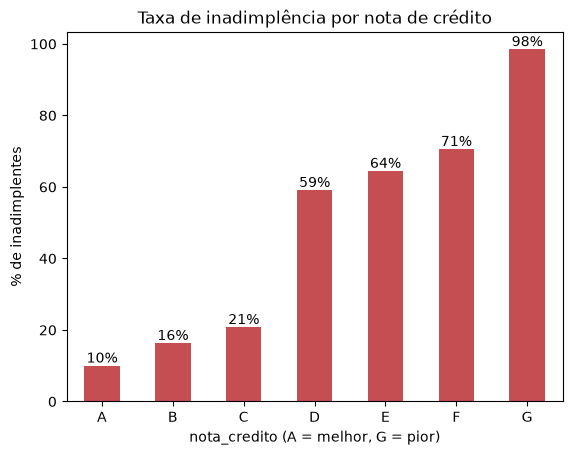

In [19]:
# Taxa de inadimplência em cada nota (A = melhor, G = pior)
taxa = df_pt.groupby("nota_credito")["inadimplente"].mean().sort_index() * 100

ax = taxa.plot(kind="bar", rot=0, color="#C44E52")
ax.bar_label(ax.containers[0], fmt="%.0f%%")
ax.set_title("Taxa de inadimplência por nota de crédito")
ax.set_xlabel("nota_credito (A = melhor, G = pior)")
ax.set_ylabel("% de inadimplentes")
plt.show()

**Observação:** quanto pior a nota de crédito, maior a inadimplência. Vai de 10% na nota A até 98% na nota G. O salto maior acontece da nota C (21%) para a D (59%). Essa coluna deve ser uma das mais importantes para o modelo.

# Diagnóstico da EDA

A base tem 32.581 clientes e é desbalanceada (78% adimplentes e 22% inadimplentes), então não vou usar a acurácia como métrica principal e vou tratar o desbalanceamento só no treino. Encontrei valores impossíveis, como idades de até 144 anos e tempo de emprego de 123 anos, que vou remover por serem erros de cadastro. Os outros valores extremos, como rendas altas e idades entre 40 e 80 anos, são reais e vou manter. As colunas `tempo_emprego_anos` e `taxa_juros` têm dados faltando, que vou preencher com a mediana dentro do pipeline, depois de separar treino e teste. Por fim, a nota de crédito, a taxa de juros e o quanto o empréstimo compromete a renda são os sinais mais fortes de inadimplência, o que reforça a criação da feature `comprometimento_renda`.